In [1]:

# Import libraries for data handling
import os
import numpy as np
import pandas as pd

# Import PyTorch for deep learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Import MobileNetV3 from torchvision
from torchvision import models

# Import tools for evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

# Import plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Check whether GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [2]:

# Define the main project folder in Google Drive
project_path = "/content/drive/MyDrive/Wafer Classification"

# Define paths for the dataset and split CSV files
dataset_path = os.path.join(project_path, "LSWMD.pkl")
splits_path = os.path.join(project_path, "splits")

# Load the training, validation, and testing split information
train_df = pd.read_csv(os.path.join(splits_path, "train.csv"))
val_df = pd.read_csv(os.path.join(splits_path, "validation.csv"))
test_df = pd.read_csv(os.path.join(splits_path, "test.csv"))

# Display the number of samples in each split
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

# Display the first five rows of the training split
print("\nTraining split preview:")
display(train_df.head())

# Check the columns available in the split files
print("\nColumns:", train_df.columns.tolist())

Training samples: 120979
Validation samples: 26116
Testing samples: 25855

Training split preview:


,row_index,lotName,label_id,label
0,50,lot3,8,none
1,51,lot3,8,none
2,52,lot3,8,none
3,53,lot3,8,none
4,54,lot3,8,none



Columns: ['row_index', 'lotName', 'label_id', 'label']


In [3]:

# Extract the unique lot names from each split
train_lots = set(train_df["lotName"].unique())
val_lots = set(val_df["lotName"].unique())
test_lots = set(test_df["lotName"].unique())

# Check for overlapping lots between training and validation
train_val_overlap = train_lots.intersection(val_lots)

# Check for overlapping lots between training and testing
train_test_overlap = train_lots.intersection(test_lots)

# Check for overlapping lots between validation and testing
val_test_overlap = val_lots.intersection(test_lots)

# Display the verification results
print("Training-Validation overlapping lots:", len(train_val_overlap))
print("Training-Testing overlapping lots:", len(train_test_overlap))
print("Validation-Testing overlapping lots:", len(val_test_overlap))

# Confirm whether all three splits are independent
if len(train_val_overlap) == 0 and len(train_test_overlap) == 0 and len(val_test_overlap) == 0:
    print("\nSUCCESS: No lot overlap. All splits are independent.")
else:
    print("\nWARNING: Lot overlap detected!")

Training-Validation overlapping lots: 0
Training-Testing overlapping lots: 0
Validation-Testing overlapping lots: 0

SUCCESS: No lot overlap. All splits are independent.


In [4]:

# Load the original WM-811K dataset from Google Drive
print("Loading WM-811K dataset...")

df = pd.read_pickle(dataset_path)

# Display the dataset dimensions
print("\nDataset loaded successfully!")
print("Original dataset shape:", df.shape)

# Display the available columns
print("\nDataset columns:")
print(df.columns.tolist())

# Display the first five rows
print("\nDataset preview:")
display(df.head())

# Check the total number of wafer maps
print("\nTotal wafer maps:", len(df))

Loading WM-811K dataset...

Dataset loaded successfully!
Original dataset shape: (811457, 6)

Dataset columns:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

Dataset preview:


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]



Total wafer maps: 811457


Original wafer shape: (53, 58)
Processed wafer shape: (64, 64)
Unique pixel values: [0 1 2]


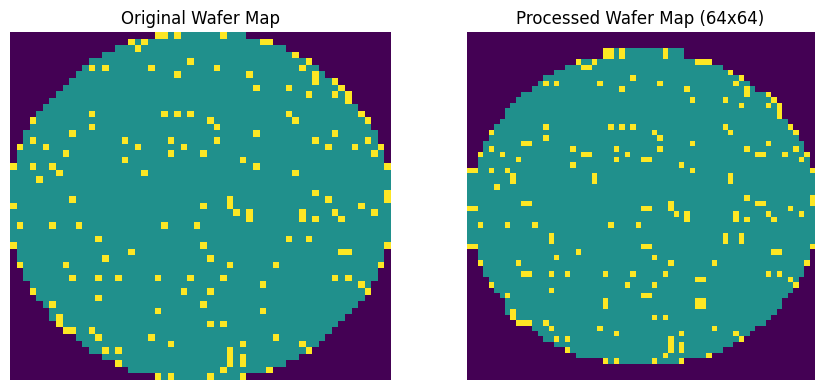

In [5]:

# Import OpenCV for image resizing
import cv2

# Function to resize and centre a wafer map
def preprocess_wafer(wafer, target_size=64):

    # Convert wafer map into a NumPy array
    wafer = np.array(wafer, dtype=np.uint8)

    # Get the original height and width
    h, w = wafer.shape

    # Calculate scaling factor while preserving aspect ratio
    scale = min(target_size / h, target_size / w)

    # Calculate the new dimensions
    new_h = max(1, int(round(h * scale)))
    new_w = max(1, int(round(w * scale)))

    # Resize using nearest-neighbor interpolation
    resized = cv2.resize(
        wafer,
        (new_w, new_h),
        interpolation=cv2.INTER_NEAREST
    )

    # Create a zero-filled 64x64 canvas
    canvas = np.zeros((target_size, target_size), dtype=np.uint8)

    # Calculate starting positions to centre the wafer map
    top = (target_size - new_h) // 2
    left = (target_size - new_w) // 2

    # Place the resized wafer map at the centre
    canvas[top:top + new_h, left:left + new_w] = resized

    return canvas


# Test preprocessing on one wafer map
sample_wafer = df.iloc[int(train_df.iloc[0]["row_index"])]["waferMap"]

processed_sample = preprocess_wafer(sample_wafer)

print("Original wafer shape:", np.array(sample_wafer).shape)
print("Processed wafer shape:", processed_sample.shape)
print("Unique pixel values:", np.unique(processed_sample))

# Display the original and processed wafer maps
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_wafer, cmap="viridis")
plt.title("Original Wafer Map")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_sample, cmap="viridis")
plt.title("Processed Wafer Map (64x64)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:

# Function to preprocess all wafer maps in a split
def preprocess_split(split_df, split_name):

    processed_maps = []

    print(f"Processing {split_name} dataset...")

    # Iterate through the row indices in the split CSV
    for i, row in enumerate(split_df["row_index"]):

        # Retrieve the original wafer map from the dataset
        wafer = df.iloc[int(row)]["waferMap"]

        # Convert it into a 64x64 image
        processed = preprocess_wafer(wafer)

        processed_maps.append(processed)

        # Display progress after every 10,000 samples
        if (i + 1) % 10000 == 0:
            print(f"{i + 1}/{len(split_df)} processed")

    # Convert the list into a NumPy array
    processed_maps = np.stack(processed_maps)

    print(f"{split_name} preprocessing completed!")
    print("Shape:", processed_maps.shape)

    return processed_maps


# Preprocess the training dataset
X_train = preprocess_split(train_df, "Training")

# Preprocess the validation dataset
X_val = preprocess_split(val_df, "Validation")

# Preprocess the testing dataset
X_test = preprocess_split(test_df, "Testing")

# Extract class labels from the split CSV files
y_train = train_df["label_id"].to_numpy(dtype=np.int64)
y_val = val_df["label_id"].to_numpy(dtype=np.int64)
y_test = test_df["label_id"].to_numpy(dtype=np.int64)

# Display final dataset dimensions
print("\nFinal dataset shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nLabel shapes:")
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

Processing Training dataset...
10000/120979 processed
20000/120979 processed
30000/120979 processed
40000/120979 processed
50000/120979 processed
60000/120979 processed
70000/120979 processed
80000/120979 processed
90000/120979 processed
100000/120979 processed
110000/120979 processed
120000/120979 processed
Training preprocessing completed!
Shape: (120979, 64, 64)
Processing Validation dataset...
10000/26116 processed
20000/26116 processed
Validation preprocessing completed!
Shape: (26116, 64, 64)
Processing Testing dataset...
10000/25855 processed
20000/25855 processed
Testing preprocessing completed!
Shape: (25855, 64, 64)

Final dataset shapes:
X_train: (120979, 64, 64)
X_val: (26116, 64, 64)
X_test: (25855, 64, 64)

Label shapes:
y_train: (120979,)
y_val: (26116,)
y_test: (25855,)


In [7]:

# Define the class names in the same order as their class IDs
class_names = [
    "Center",
    "Donut",
    "Edge-Loc",
    "Edge-Ring",
    "Loc",
    "Near-full",
    "Random",
    "Scratch",
    "none"
]

# Count the number of training samples in each class
class_counts = np.bincount(y_train, minlength=len(class_names))

# Display the training class distribution
print("Training class distribution:\n")

for i, name in enumerate(class_names):
    print(f"{name:12s}: {class_counts[i]}")

# Calculate class weights to handle class imbalance
num_classes = len(class_names)
total_samples = len(y_train)

class_weights = total_samples / (num_classes * class_counts)

# Limit very large weights to avoid unstable training
class_weights = np.minimum(class_weights, 20.0)

# Convert class weights into a PyTorch tensor
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

# Display the calculated weights
print("\nClass weights:")

for name, weight in zip(class_names, class_weights):
    print(f"{name:12s}: {weight:.4f}")

print("\nClass weights tensor created successfully!")

Training class distribution:

Center      : 3008
Donut       : 366
Edge-Loc    : 3630
Edge-Ring   : 6871
Loc         : 2411
Near-full   : 107
Random      : 614
Scratch     : 871
none        : 103101

Class weights:
Center      : 4.4688
Donut       : 20.0000
Edge-Loc    : 3.7031
Edge-Ring   : 1.9564
Loc         : 5.5753
Near-full   : 20.0000
Random      : 20.0000
Scratch     : 15.4330
none        : 0.1304

Class weights tensor created successfully!


In [8]:

# Define a custom PyTorch Dataset class
class WaferDataset(Dataset):

    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        # Return the total number of samples
        return len(self.labels)

    def __getitem__(self, index):

        # Retrieve one wafer map
        image = torch.tensor(self.images[index], dtype=torch.long)

        # Convert pixel values 0, 1, 2 into three channels
        image = torch.nn.functional.one_hot(
            image, num_classes=3
        )

        # Change dimensions from (64, 64, 3) to (3, 64, 64)
        image = image.permute(2, 0, 1).float()

        # Retrieve the corresponding class label
        label = torch.tensor(self.labels[index], dtype=torch.long)

        return image, label


# Create PyTorch datasets
train_dataset = WaferDataset(X_train, y_train)
val_dataset = WaferDataset(X_val, y_val)
test_dataset = WaferDataset(X_test, y_test)

# Verify one sample
sample_image, sample_label = train_dataset[0]

print("PyTorch Dataset created successfully!")
print("Image shape:", sample_image.shape)
print("Image data type:", sample_image.dtype)
print("Label:", sample_label.item())
print("Number of classes:", num_classes)

PyTorch Dataset created successfully!
Image shape: torch.Size([3, 64, 64])
Image data type: torch.float32
Label: 8
Number of classes: 9


In [9]:

# Set the batch size
batch_size = 128

# Enable pinned memory when using the GPU
pin_memory = torch.cuda.is_available()

# Create the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=pin_memory
)

# Create the validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=pin_memory
)

# Create the testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=pin_memory
)

# Display DataLoader information
print("DataLoaders created successfully!")

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

# Retrieve one batch to verify the dimensions
images, labels = next(iter(train_loader))

print("\nBatch verification:")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

DataLoaders created successfully!

Training batches: 946
Validation batches: 205
Testing batches: 202

Batch verification:
Image batch shape: torch.Size([128, 3, 64, 64])
Label batch shape: torch.Size([128])
Image data type: torch.float32
Label data type: torch.int64


In [10]:

# Load MobileNetV3-Small without pretrained weights
mobilenet = models.mobilenet_v3_small(weights=None)

# Get the number of input features in the final classification layer
in_features = mobilenet.classifier[3].in_features

# Replace the final layer with 9 output classes
mobilenet.classifier[3] = nn.Linear(
    in_features,
    num_classes
)

# Move the model to the T4 GPU
mobilenet = mobilenet.to(device)

# Count the trainable parameters
total_params = sum(
    p.numel() for p in mobilenet.parameters()
    if p.requires_grad
)

# Display model information
print("MobileNetV3-Small model created successfully!")

print("\nModel:", mobilenet.__class__.__name__)
print("Number of output classes:", num_classes)
print("Trainable parameters:", f"{total_params:,}")
print("Device:", next(mobilenet.parameters()).device)

# Display the final classification layer
print("\nFinal classification layer:")
print(mobilenet.classifier[3])

MobileNetV3-Small model created successfully!

Model: MobileNetV3
Number of output classes: 9
Trainable parameters: 1,527,081
Device: cuda:0

Final classification layer:
Linear(in_features=1024, out_features=9, bias=True)


In [11]:

# Define the weighted Cross Entropy Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# Define the Adam optimizer
optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Set training parameters
num_epochs = 20
patience = 5

# Define the checkpoint directory
checkpoint_dir = os.path.join(project_path, "checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)

# Define the MobileNetV3 checkpoint path
checkpoint_path = os.path.join(
    checkpoint_dir,
    "mobilenetv3_small.pth"
)

# Initialize variables for training
best_val_loss = float("inf")
early_stop_counter = 0

# Store training and validation metrics
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print("Training configuration completed!")
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])
print("Maximum epochs:", num_epochs)
print("Early stopping patience:", patience)
print("Checkpoint path:", checkpoint_path)

Training configuration completed!
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Weight decay: 0.0001
Maximum epochs: 20
Early stopping patience: 5
Checkpoint path: /content/drive/MyDrive/Wafer Classification/checkpoints/mobilenetv3_small.pth


In [12]:

# Import tqdm to display training progress
from tqdm.auto import tqdm

# Function to train the model for one epoch
def train_one_epoch(model, loader, criterion, optimizer, device):

    # Set the model to training mode
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    # Iterate through training batches
    progress_bar = tqdm(loader, desc="Training")

    for images, labels in progress_bar:

        # Move images and labels to GPU
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previously calculated gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Calculate predictions
        predictions = outputs.argmax(dim=1)

        # Update loss and accuracy statistics
        running_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress_bar.set_postfix(loss=loss.item())

    # Calculate average loss and accuracy
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


# Function to evaluate the model on validation data
def validate_one_epoch(model, loader, criterion, device):

    # Set the model to evaluation mode
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient calculation during validation
    with torch.no_grad():

        progress_bar = tqdm(loader, desc="Validation")

        for images, labels in progress_bar:

            # Move images and labels to GPU
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Get predicted classes
            predictions = outputs.argmax(dim=1)

            # Update statistics
            running_loss += loss.item() * images.size(0)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    # Calculate average loss and accuracy
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions defined successfully!")

Training and validation functions defined successfully!


In [13]:

# Start MobileNetV3-Small training
print("Starting MobileNetV3-Small training...\n")

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 50)

    # Train the model for one epoch
    train_loss, train_acc = train_one_epoch(
        mobilenet,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validate the model
    val_loss, val_acc = validate_one_epoch(
        mobilenet,
        val_loader,
        criterion,
        device
    )

    # Store training and validation metrics
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Display epoch results
    print(f"\nTraining Loss:   {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc * 100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc * 100:.2f}%")

    # Save checkpoint if validation loss improves
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        early_stop_counter = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": mobilenet.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "history": history
        }, checkpoint_path)

        print("Best model checkpoint saved!")

    else:

        early_stop_counter += 1

        print("Validation loss did not improve.")
        print("Early stopping counter:", early_stop_counter)

    # Stop training if validation loss does not improve
    if early_stop_counter >= patience:

        print("\nEarly stopping triggered!")
        break

print("\nMobileNetV3-Small training completed!")
print("Best validation loss:", best_val_loss)
print("Checkpoint saved at:", checkpoint_path)

Starting MobileNetV3-Small training...


Epoch 1/20
--------------------------------------------------


Training:   0%|          | 0/946 [00:00<?, ?it/s]

Validation:   0%|          | 0/205 [00:00<?, ?it/s]


Training Loss:   1.4567
Training Accuracy: 60.84%
Validation Loss: 1.3879
Validation Accuracy: 47.61%
Best model checkpoint saved!

Epoch 2/20
--------------------------------------------------


Training:   0%|          | 0/946 [00:00<?, ?it/s]

Validation:   0%|          | 0/205 [00:00<?, ?it/s]

... (22 outputs left out)

Training:   0%|          | 0/946 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7861ad485c60>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7861ad485c60>
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():self._shutdown_workers()
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    AssertionErrorif w.is_alive():: 
can only test a child process  File "/usr/lib/p

Validation:   0%|          | 0/205 [00:00<?, ?it/s]


Training Loss:   0.2538
Training Accuracy: 82.96%
Validation Loss: 1.4326
Validation Accuracy: 77.37%
Validation loss did not improve.
Early stopping counter: 5

Early stopping triggered!

MobileNetV3-Small training completed!
Best validation loss: 1.0873504644843224
Checkpoint saved at: /content/drive/MyDrive/Wafer Classification/checkpoints/mobilenetv3_small.pth


In [14]:

# Load the best saved MobileNetV3 checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Restore the best model weights
mobilenet.load_state_dict(checkpoint["model_state_dict"])

# Set the model to evaluation mode
mobilenet.eval()

# Display checkpoint information
print("Best MobileNetV3 checkpoint loaded successfully!")

print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Model device:", next(mobilenet.parameters()).device)

Best MobileNetV3 checkpoint loaded successfully!
Best epoch: 4
Best validation loss: 1.0873504644843224
Model device: cuda:0


In [15]:

# Set the model to evaluation mode
mobilenet.eval()

# Store actual labels and predicted labels
all_labels = []
all_predictions = []

# Disable gradient calculation during testing
with torch.no_grad():

    for images, labels in tqdm(test_loader, desc="Testing MobileNetV3"):

        # Move images to GPU
        images = images.to(device, non_blocking=True)

        # Generate model predictions
        outputs = mobilenet(images)

        # Get the predicted class for each image
        predictions = outputs.argmax(dim=1)

        # Store predictions and actual labels
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

# Calculate macro and weighted metrics
macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

weighted_precision, weighted_recall, weighted_f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

# Display test results
print("\nMobileNetV3-Small Test Results")
print("=" * 45)

print("Test samples:", len(all_labels))
print(f"Test Accuracy:       {test_accuracy * 100:.2f}%")
print(f"Macro Precision:     {macro_precision:.4f}")
print(f"Macro Recall:        {macro_recall:.4f}")
print(f"Macro F1 Score:      {macro_f1:.4f}")
print(f"Weighted Precision:  {weighted_precision:.4f}")
print(f"Weighted Recall:     {weighted_recall:.4f}")
print(f"Weighted F1 Score:   {weighted_f1:.4f}")

# Display class-wise classification report
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

Testing MobileNetV3:   0%|          | 0/202 [00:00<?, ?it/s]


MobileNetV3-Small Test Results
Test samples: 25855
Test Accuracy:       72.49%
Macro Precision:     0.5029
Macro Recall:        0.7028
Macro F1 Score:      0.5538
Weighted Precision:  0.9115
Weighted Recall:     0.7249
Weighted F1 Score:   0.7950

Classification Report:

              precision    recall  f1-score   support

      Center       0.48      0.88      0.62       603
       Donut       0.55      0.80      0.65        83
    Edge-Loc       0.23      0.55      0.33       772
   Edge-Ring       0.82      0.91      0.86      1432
         Loc       0.16      0.44      0.24       576
   Near-full       0.73      0.73      0.73        15
      Random       0.54      0.91      0.68       131
     Scratch       0.02      0.38      0.04       177
        none       0.98      0.72      0.83     22066

    accuracy                           0.72     25855
   macro avg       0.50      0.70      0.55     25855
weighted avg       0.91      0.72      0.80     25855



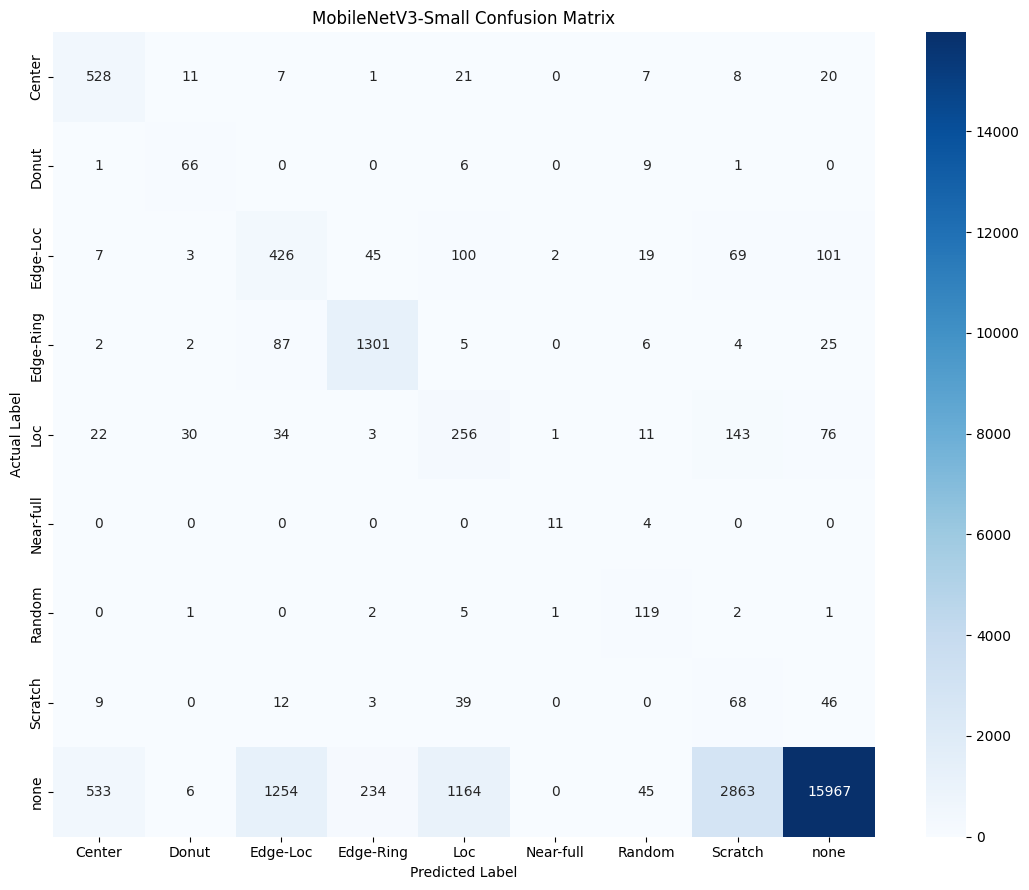

Confusion matrix saved successfully!


In [16]:

# Calculate the confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

# Create the results directory
results_dir = os.path.join(project_path, "results")
os.makedirs(results_dir, exist_ok=True)

# Plot the confusion matrix
plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV3-Small Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

# Save the confusion matrix
plt.savefig(
    os.path.join(results_dir, "mobilenetv3_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

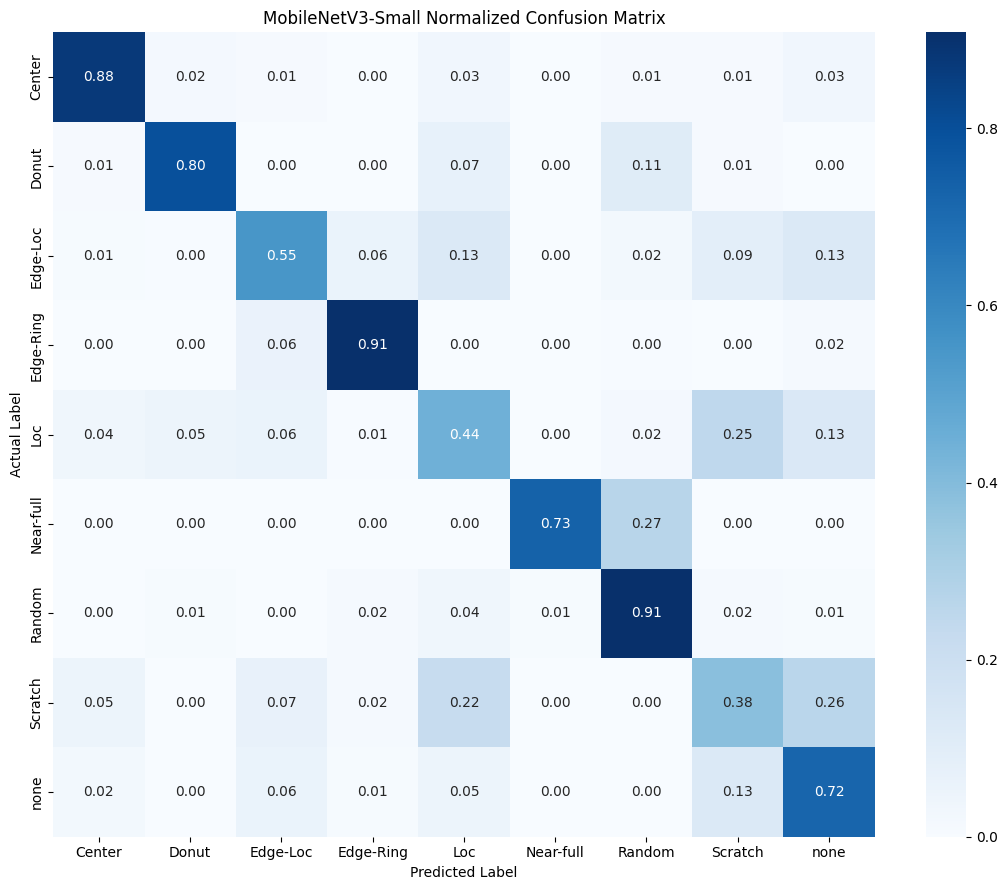

Normalized confusion matrix saved successfully!


In [17]:

# Normalize the confusion matrix row-wise
cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

# Plot the normalized confusion matrix
plt.figure(figsize=(11, 9))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV3-Small Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

# Save the normalized confusion matrix
plt.savefig(
    os.path.join(results_dir, "mobilenetv3_normalized_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Normalized confusion matrix saved successfully!")

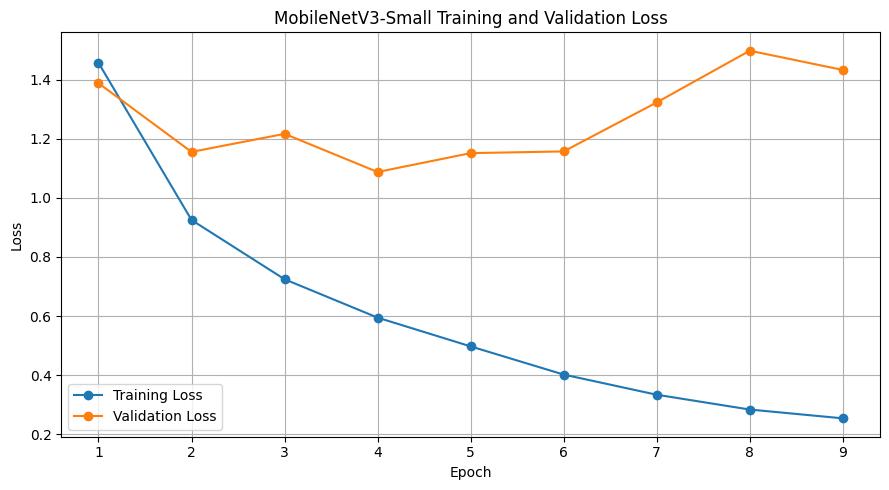

Loss graph saved successfully!


In [18]:

# Generate epoch numbers
epochs = range(1, len(history["train_loss"]) + 1)

# Plot training and validation loss
plt.figure(figsize=(9, 5))

plt.plot(epochs, history["train_loss"], marker="o",
         label="Training Loss")

plt.plot(epochs, history["val_loss"], marker="o",
         label="Validation Loss")

plt.title("MobileNetV3-Small Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save the loss graph
plt.savefig(
    os.path.join(results_dir, "mobilenetv3_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss graph saved successfully!")

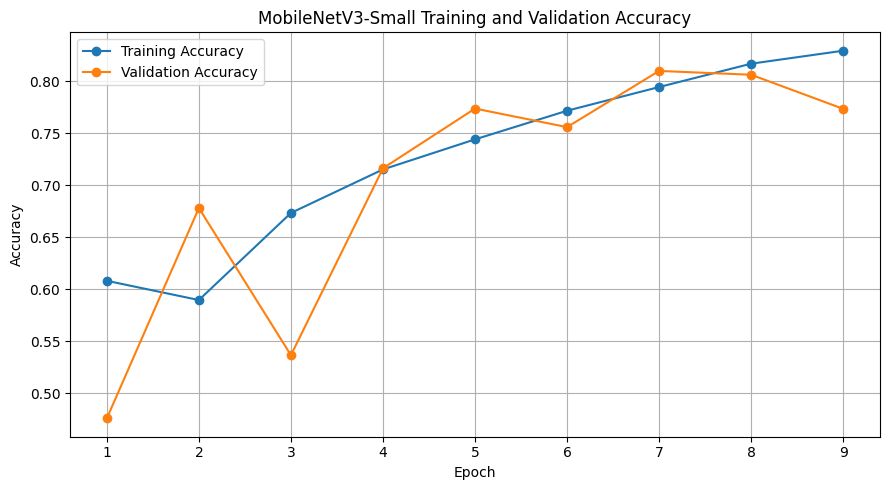

Accuracy graph saved successfully!


In [19]:

# Plot training and validation accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("MobileNetV3-Small Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save the accuracy graph
plt.savefig(
    os.path.join(results_dir, "mobilenetv3_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy graph saved successfully!")

In [20]:

# Create a comparison of all three models
comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "ResNet-18",
        "MobileNetV3-Small"
    ],
    "Test Accuracy (%)": [
        88.59,
        91.00,
        test_accuracy * 100
    ],
    "Macro Precision": [
        0.5866,
        0.61,
        macro_precision
    ],
    "Macro Recall": [
        0.8227,
        0.88,
        macro_recall
    ],
    "Macro F1 Score": [
        0.6579,
        0.70,
        macro_f1
    ],
    "Weighted F1 Score": [
        0.91,
        0.92,
        weighted_f1
    ]
})

# Display the comparison table
print("FINAL MODEL COMPARISON")
display(comparison)

# Save comparison as CSV
comparison_path = os.path.join(
    results_dir,
    "model_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print("\nComparison table saved successfully!")
print("Saved at:", comparison_path)

FINAL MODEL COMPARISON


,Model,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1 Score,Weighted F1 Score
0,Custom CNN,88.59000,0.586600,0.822700,0.65790,0.910000
1,ResNet-18,91.00000,0.610000,0.880000,0.70000,0.920000
2,MobileNetV3-Small,72.48888,0.502909,0.702788,0.55383,0.795012



Comparison table saved successfully!
Saved at: /content/drive/MyDrive/Wafer Classification/results/model_comparison.csv


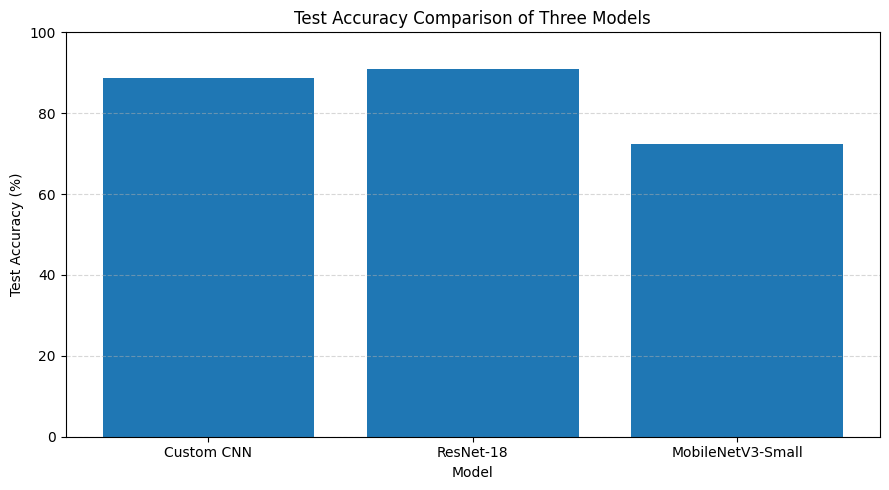

Model accuracy comparison graph saved successfully!


In [21]:

# Plot test accuracy comparison
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"]
)

plt.title("Test Accuracy Comparison of Three Models")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save the comparison graph
plt.savefig(
    os.path.join(results_dir, "model_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model accuracy comparison graph saved successfully!")

In [22]:

# Define the important project directories
checkpoint_dir = os.path.join(project_path, "checkpoints")
results_dir = os.path.join(project_path, "results")

# List all saved model checkpoints
print("SAVED MODEL CHECKPOINTS")
print("=" * 45)

for filename in os.listdir(checkpoint_dir):
    filepath = os.path.join(checkpoint_dir, filename)

    if os.path.isfile(filepath):
        print(filename, "-", round(os.path.getsize(filepath) / (1024**2), 2), "MB")


# List all saved result files
print("\nSAVED PROJECT RESULTS")
print("=" * 45)

for filename in sorted(os.listdir(results_dir)):
    filepath = os.path.join(results_dir, filename)

    if os.path.isfile(filepath):
        print(filename)


# Verify the MobileNetV3 checkpoint
print("\nCHECKPOINT VERIFICATION")

if os.path.exists(checkpoint_path):
    print("MobileNetV3 checkpoint: VERIFIED")
else:
    print("MobileNetV3 checkpoint: MISSING")

print("\nProject verification completed!")

SAVED MODEL CHECKPOINTS
custom_cnn.pth - 0.37 MB
resnet18.pth - 128.0 MB
mobilenetv3_small.pth - 17.72 MB

SAVED PROJECT RESULTS
custom_cnn_confusion_matrix.png
custom_cnn_metrics.csv
custom_cnn_normalized_confusion_matrix.png
mobilenetv3_accuracy.png
mobilenetv3_confusion_matrix.png
mobilenetv3_loss.png
mobilenetv3_normalized_confusion_matrix.png
model_accuracy_comparison.png
model_comparison.csv
resnet18_accuracy.png
resnet18_confusion_matrix.png
resnet18_loss.png
resnet18_normalized_confusion_matrix.png

CHECKPOINT VERIFICATION
MobileNetV3 checkpoint: VERIFIED

Project verification completed!
